# CNN 최적화 종합실습 — 문제 (baseline 제공)
[과적합·클래스 불균형 개선 · 2인 1조]

- 팀 번호 / 캠퍼스 / 반: 5조 / 판교캠퍼스 / 4반
- 팀원 1 (이름 / 학번): 권하림 / P106
- 팀원 2 (이름 / 학번): 채석현 / P129

> **상황**: 제공된 baseline 은 학습 데이터는 잘 맞히지만 테스트에서 성능이 떨어집니다(과적합).
> 게다가 클래스별 데이터 수가 크게 **불균형**합니다(소수 클래스는 100장뿐).

> **목표**: 데이터 상황을 진단하고, 개선 기법을 **직접 골라 실험**해 성능(특히 소수 클래스)을 끌어올리세요.

> **원칙**: 학습·평가 코드는 그대로 두고, **한 번에 하나씩만** 바꿔가며 효과를 확인합니다.

## 데이터셋 소개 — CIFAR-10

**CIFAR-10** 은 딥러닝 입문에 널리 쓰이는 이미지 데이터셋입니다.

- **10개 사물 종류**: 비행기 · 자동차 · 새 · 고양이 · 사슴 · 개 · 개구리 · 말 · 배 · 트럭
- **이미지 크기**: 32×32 픽셀, 컬러(RGB 3채널) — 작고 가벼워 실습에 적합
- **원래 규모**: 클래스마다 6,000장씩 총 60,000장 (학습 50,000 / 테스트 10,000)으로 **원본은 균형 데이터**
- **자동 다운로드(최초 1회)**: 아래 '데이터 다운로드' 셀이 처음 한 번만 내려받고, 다시 실행할 때는 자동으로 건너뜁니다(약 170MB). 별도 파일 준비 불필요.

> **실제 데이터를 수집하여 진행하는 것이 현실적으로 힘들기 때문에 실습을 위해 일부러 불균형하게 만듭니다.**

> 일부 클래스(예: 배·트럭)의 학습 이미지를 100장까지 줄여, 실제 현장의 *불량 분류*처럼
> "데이터가 적은 소수 클래스" 상황을 재현합니다. baseline 이 소수 클래스를 잘 못 맞히는 이유가 여기에 있습니다.

## 1. 준비 — 실행 환경

In [1]:
# ── 환경 준비 ─────────────────────────────────────────────
# 실행 환경 자동 감지: NVIDIA GPU(cuda) → 맥북 Apple GPU(mps) → CPU 순으로 선택
# Colab 사용 시: 런타임 → 런타임 유형 변경 → 하드웨어 가속기 = GPU 권장
# Colab에서 구글 드라이브에 결과를 저장하려면 아래 2줄의 주석을 해제하세요. google drive 연동합니다.
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
import sys
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, f1_score, recall_score

# ── 한글 폰트 설정 (그래프 제목이 □□□ 로 깨지는 것 방지) ──
from matplotlib import font_manager
if "google.colab" in sys.modules:                  # Colab: 나눔고딕 설치 후 등록
    import subprocess
    subprocess.run("apt-get -qq install -y fonts-nanum", shell=True, check=False)
    font_manager.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
_fonts = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:   # 윈도우 / 맥 / 리눅스·Colab
    if _f in _fonts:
        matplotlib.rc("font", family=_f); print("한글 폰트:", _f); break
else:
    print("[한글 폰트 참고] 한글 폰트를 찾지 못했습니다. 그래프 제목이 깨질 수 있어요.")
matplotlib.rcParams["axes.unicode_minus"] = False            # 음수 부호(-) 깨짐 방지

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)

# GPU가 있으면 자동 사용, 없으면 CPU — Colab / 일반 PC / 맥북 모두 실행 가능
if torch.cuda.is_available():
    device = torch.device("cuda")            # Colab GPU 또는 NVIDIA GPU PC
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")             # 맥북(Apple Silicon) GPU
else:
    device = torch.device("cpu")             # CPU (실행은 되지만 느릴 수 있음)
print("device:", device)

# DataLoader 워커 수: GPU 환경만 멀티프로세싱 사용(맥/CPU/노트북 호환 위해 그 외엔 0)
NUM_WORKERS = 2 if device.type == "cuda" else 0


한글 폰트: NanumGothic
device: cuda


In [3]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
CLASSES = ['airplane','auto','bird','cat','deer','dog','frog','horse','ship','truck']
MINORITY = [8, 9]   # 데이터가 가장 적은(소수) 클래스

## 1-2. 데이터 다운로드 (최초 1회만 실행)

CIFAR-10 데이터를 내려받는 단계입니다. **이미 받아 둔 데이터가 있으면 자동으로 건너뜁니다** — 노트북을 처음부터 다시 실행해도 다시 다운로드하지 않습니다. (약 170MB)

> 아래 셀을 **한 번만** 실행하면 됩니다. 이후 진단·실험 셀들은 받아 둔 데이터를 바로 사용합니다.

In [4]:
# ── 데이터 다운로드 (최초 1회만) ──────────────────────────────────
# 이미 받아 둔 CIFAR-10 데이터가 있으면 다운로드를 건너뜁니다.
# → 노트북을 처음부터 다시 실행해도 데이터를 다시 내려받지 않습니다.
import os
from torchvision import datasets

DATA_ROOT = "./data"   # 데이터 저장 위치 (아래 실습 셀들과 동일하게 사용)

# 압축이 풀린 실제 데이터 폴더가 있으면 '이미 준비됨'으로 판단
_ready = os.path.isdir(os.path.join(DATA_ROOT, "cifar-10-batches-py"))

if _ready:
    print(f"✓ 이미 준비된 CIFAR-10 데이터가 있어 다운로드를 건너뜁니다  →  {os.path.abspath(DATA_ROOT)}")
else:
    print("↓ CIFAR-10 데이터가 없어 다운로드를 시작합니다 (약 170MB) …")
    datasets.CIFAR10(DATA_ROOT, train=True,  download=True)
    datasets.CIFAR10(DATA_ROOT, train=False, download=True)
    print("✓ 다운로드 완료.")

↓ CIFAR-10 데이터가 없어 다운로드를 시작합니다 (약 170MB) …


100%|██████████| 170M/170M [31:34<00:00, 90.0kB/s]


✓ 다운로드 완료.


## 2. 진단 ① — 불균형 데이터 만들기와 분포 확인
Train/Valid/Test 3분할로 구성합니다. 아래 분포 그래프에서 클래스별 수가 얼마나 차이 나는지 보세요.

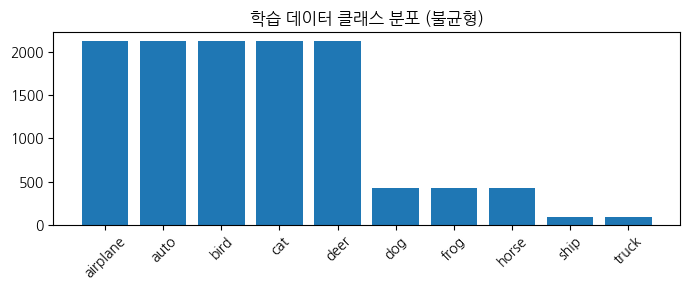

클래스별 학습 수: {'airplane': 2125, 'auto': 2125, 'bird': 2125, 'cat': 2125, 'deer': 2125, 'dog': 425, 'frog': 425, 'horse': 425, 'ship': 85, 'truck': 85}


In [5]:
# ── 불균형 데이터 만들기 + Train/Valid/Test 3분할 (완성) ──
# 실제 '불량 분류'처럼 클래스별 수를 일부러 크게 다르게 구성합니다.
COUNTS = {0:2500,1:2500,2:2500,3:2500,4:2500, 5:500,6:500,7:500, 8:100,9:100}

_raw = datasets.CIFAR10("./data", train=True, download=False)
_targets = np.array(_raw.targets)
rng = np.random.default_rng(SEED)
train_idx, valid_idx = [], []
for c, n in COUNTS.items():
    ci = rng.permutation(np.where(_targets == c)[0])[:n]
    k = max(1, int(n * 0.15))          # 15%는 검증(Valid)용
    valid_idx += ci[:k].tolist(); train_idx += ci[k:].tolist()
rng.shuffle(train_idx); rng.shuffle(valid_idx)

# 손실 가중치(역빈도) — '클래스 불균형 처리'에서 사용
_cnt = np.bincount([_targets[i] for i in train_idx], minlength=10)
CLASS_WEIGHTS = torch.tensor((_cnt.sum() / (10 * _cnt)), dtype=torch.float32)

def get_loaders(use_aug=False, batch=128):
    aug = [transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()] if use_aug else []
    tf_tr = transforms.Compose(aug + [transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    tf_te = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    tr_full = datasets.CIFAR10("./data", train=True,  download=False, transform=tf_tr)
    va_full = datasets.CIFAR10("./data", train=True,  download=False, transform=tf_te)
    te_full = datasets.CIFAR10("./data", train=False, download=False, transform=tf_te)
    return (DataLoader(Subset(tr_full, train_idx), batch_size=batch, shuffle=True,  num_workers=NUM_WORKERS),
            DataLoader(Subset(va_full, valid_idx), batch_size=256,  shuffle=False, num_workers=NUM_WORKERS),
            DataLoader(te_full,                    batch_size=256,  shuffle=False, num_workers=NUM_WORKERS))

# 클래스 분포 확인 (진단 1)
plt.figure(figsize=(7,3))
plt.bar(CLASSES, [_cnt[c] for c in range(10)])
plt.title("학습 데이터 클래스 분포 (불균형)"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
print("클래스별 학습 수:", {CLASSES[c]: int(_cnt[c]) for c in range(10)})

## 3. 지표 — Accuracy만으로 부족한 이유
정확도 외에 **Macro-F1**, **클래스별 Recall** 을 함께 봅니다. (아래 함수는 그대로 실행해도 됩니다.)

> **Macro-F1**: 클래스마다 F1(정밀도·재현율의 조화평균)을 따로 구한 뒤 **클래스 크기와 무관하게 단순 평균**한 값. 소수 클래스도 다수 클래스와 같은 비중으로 반영되므로, 불균형에서 소수 클래스를 놓치면 점수가 크게 떨어집니다(= Accuracy보다 엄격한 기준).

In [6]:
# ── 성능 지표 함수 (완성) : Accuracy / Macro-F1 / 클래스별 Recall ──
@torch.no_grad()
def evaluate_metrics(model, loader):
    model.eval(); ys, ps = [], []
    for x, y in loader:
        p = model(x.to(device)).argmax(1).cpu().numpy()
        ps.append(p); ys.append(y.numpy())
    y, p = np.concatenate(ys), np.concatenate(ps)
    acc = accuracy_score(y, p)
    mf1 = f1_score(y, p, average="macro")
    rec = recall_score(y, p, labels=list(range(10)), average=None, zero_division=0)
    return acc, mf1, rec

## 4. 모델·실험 실행기 (그대로 실행해도 됩니다)

In [7]:
# ── 모델 (완성) : 옵션으로 BatchNorm·Dropout 켜기 ──
class CifarCNN(nn.Module):
    def __init__(self, use_bn=False, p_drop=0.0):
        super().__init__()
        self.use_bn = use_bn
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1);  self.conv2 = nn.Conv2d(32, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1); self.conv4 = nn.Conv2d(64, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2); self.drop = nn.Dropout(p_drop)
        self.fc1 = nn.Linear(64*8*8, 256); self.fc2 = nn.Linear(256, 10)
        if use_bn:
            self.bn1=nn.BatchNorm2d(32); self.bn2=nn.BatchNorm2d(32)
            self.bn3=nn.BatchNorm2d(64); self.bn4=nn.BatchNorm2d(64)
    def _act(self, x, conv, bn):
        x = conv(x)
        if self.use_bn: x = bn(x)
        return F.relu(x)
    def forward(self, x):
        x = self._act(x, self.conv1, getattr(self,"bn1",None))
        x = self._act(x, self.conv2, getattr(self,"bn2",None)); x = self.pool(x)
        x = self._act(x, self.conv3, getattr(self,"bn3",None))
        x = self._act(x, self.conv4, getattr(self,"bn4",None)); x = self.pool(x)
        x = torch.flatten(x, 1); x = F.relu(self.fc1(x)); x = self.drop(x)
        return self.fc2(x)

In [8]:
# ── 실험 실행기 (완성 — 수정하지 않고 사용하세요) ─────────────────
# 옵션을 바꿔 부르면 한 번의 실험이 되고, 결과가 RESULTS 표에 쌓입니다.
RESULTS = []
def run_experiment(name, use_bn=False, dropout_p=0.0, weight_decay=0.0,
                   use_aug=False, use_class_weight=False, patience=99, epochs=25):
    torch.manual_seed(SEED)
    tr, va, te = get_loaders(use_aug=use_aug)
    model = CifarCNN(use_bn=use_bn, p_drop=dropout_p).to(device)
    w = CLASS_WEIGHTS.to(device) if use_class_weight else None
    criterion = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=weight_decay)
    best_f1, best_state, wait, hist = -1, None, 0, []
    print(f"===== {name} =====")
    for ep in range(1, epochs+1):
        model.train()
        for x, y in tr:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = criterion(model(x), y); loss.backward(); opt.step()
        tr_acc, _, _ = evaluate_metrics(model, tr)
        va_acc, va_f1, _ = evaluate_metrics(model, va)
        hist.append((tr_acc, va_acc))
        print(f"  epoch {ep:2d}  train_acc={tr_acc:.3f}  valid_acc={va_acc:.3f}  valid_MacroF1={va_f1:.3f}")
        if va_f1 > best_f1 + 1e-4:
            best_f1, wait = va_f1, 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                print(f"  → Early stop (epoch {ep})"); break
    if best_state: model.load_state_dict(best_state)
    acc, mf1, rec = evaluate_metrics(model, te)
    minr = float(rec[MINORITY].mean())
    RESULTS.append({"실험": name, "test_Acc": round(acc,3), "test_MacroF1": round(mf1,3),
                    "소수클래스_Recall": round(minr,3)})
    h = np.array(hist)
    plt.figure(figsize=(5,3)); plt.plot(h[:,0],marker="o",label="train_acc")
    plt.plot(h[:,1],marker="s",label="valid_acc"); plt.title(name)
    plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show()
    print(f"[{name}] test Acc={acc:.3f} | Macro-F1={mf1:.3f} | 소수클래스 Recall={minr:.3f}")
    print("  클래스별 Recall:", {CLASSES[i]: round(float(rec[i]),2) for i in range(10)})
    return model

## 5. 진단 ② — baseline 실행
먼저 아무 기법도 안 쓴 baseline 을 돌려 **기준값**으로 삼고, 학습곡선(과적합)과 소수 클래스 Recall(불균형)을 관찰하세요.

===== 0_baseline =====
  epoch  1  train_acc=0.504  valid_acc=0.498  valid_MacroF1=0.275
  epoch  2  train_acc=0.594  valid_acc=0.593  valid_MacroF1=0.340
  epoch  3  train_acc=0.658  valid_acc=0.646  valid_MacroF1=0.430
  epoch  4  train_acc=0.698  valid_acc=0.664  valid_MacroF1=0.444
  epoch  5  train_acc=0.718  valid_acc=0.680  valid_MacroF1=0.460
  epoch  6  train_acc=0.775  valid_acc=0.696  valid_MacroF1=0.480
  epoch  7  train_acc=0.814  valid_acc=0.693  valid_MacroF1=0.486
  epoch  8  train_acc=0.848  valid_acc=0.707  valid_MacroF1=0.504
  epoch  9  train_acc=0.892  valid_acc=0.707  valid_MacroF1=0.510
  epoch 10  train_acc=0.933  valid_acc=0.708  valid_MacroF1=0.517
  epoch 11  train_acc=0.956  valid_acc=0.688  valid_MacroF1=0.520
  epoch 12  train_acc=0.979  valid_acc=0.703  valid_MacroF1=0.537
  epoch 13  train_acc=0.979  valid_acc=0.691  valid_MacroF1=0.500
  epoch 14  train_acc=0.981  valid_acc=0.695  valid_MacroF1=0.522
  epoch 15  train_acc=0.986  valid_acc=0.689  valid_M

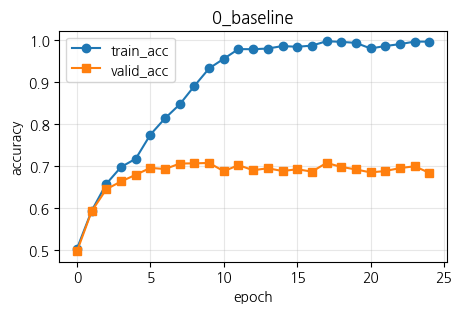

[0_baseline] test Acc=0.526 | Macro-F1=0.494 | 소수클래스 Recall=0.159
  클래스별 Recall: {'airplane': 0.81, 'auto': 0.9, 'bird': 0.64, 'cat': 0.67, 'deer': 0.7, 'dog': 0.18, 'frog': 0.55, 'horse': 0.49, 'ship': 0.16, 'truck': 0.16}


CifarCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)

In [9]:
# baseline: 아무 개선 기법도 쓰지 않은 기본 모델 (기준값)
run_experiment("0_baseline", epochs=25)

## 6. 최적화 실험 — 최적화 방안을 다양하게 설계하고 실험해보세요.
아래 A~D 는 **정답이 정해진 순서가 아니라 선택지 이며 참고할 수 있는 방법들**입니다. 각 방안의 고민을 팀이 논의하면서 또 다른 방법들을 설계해 보세요. 다음 코드를 참고하여 실행할 때 , 새로운 셀을 추가하며 다양한
값을 바꿔 실행하고 표(Accuracy·Macro-F1·소수 Recall)의 변화를 기록하세요.

### 방안 A. 클래스 불균형 처리 (손실 가중치)
데이터가 적은 클래스를 틀렸을 때 **더 큰 벌점**을 줘서 소수 클래스도 배우게 합니다. (`use_class_weight=True`)

> **고민해볼 점**
> - 소수 클래스 Recall은 올라가는데, 다수 클래스나 전체 Accuracy가 희생되지는 않나요?
> - "좋아졌다"를 Accuracy로 볼지 **Macro-F1**로 볼지에 따라 결론이 달라집니다.

===== A_클래스가중치 =====
  epoch  1  train_acc=0.508  valid_acc=0.496  valid_MacroF1=0.277
  epoch  2  train_acc=0.591  valid_acc=0.591  valid_MacroF1=0.342
  epoch  3  train_acc=0.657  valid_acc=0.642  valid_MacroF1=0.430
  epoch  4  train_acc=0.700  valid_acc=0.658  valid_MacroF1=0.444
  epoch  5  train_acc=0.709  valid_acc=0.675  valid_MacroF1=0.445
  epoch  6  train_acc=0.772  valid_acc=0.692  valid_MacroF1=0.470
  epoch  7  train_acc=0.819  valid_acc=0.699  valid_MacroF1=0.476
  epoch  8  train_acc=0.857  valid_acc=0.715  valid_MacroF1=0.517
  epoch  9  train_acc=0.890  valid_acc=0.712  valid_MacroF1=0.503
  epoch 10  train_acc=0.924  valid_acc=0.702  valid_MacroF1=0.524
  epoch 11  train_acc=0.954  valid_acc=0.690  valid_MacroF1=0.511
  epoch 12  train_acc=0.978  valid_acc=0.698  valid_MacroF1=0.512
  epoch 13  train_acc=0.985  valid_acc=0.695  valid_MacroF1=0.511
  epoch 14  train_acc=0.982  valid_acc=0.704  valid_MacroF1=0.528
  epoch 15  train_acc=0.995  valid_acc=0.695  valid_Mac

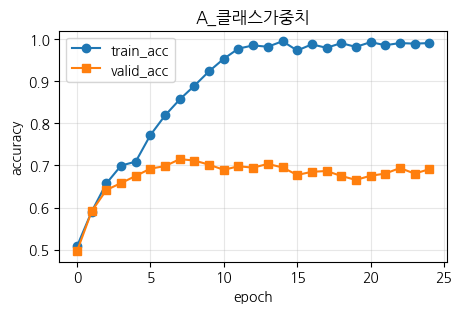

[A_클래스가중치] test Acc=0.519 | Macro-F1=0.495 | 소수클래스 Recall=0.201
  클래스별 Recall: {'airplane': 0.83, 'auto': 0.89, 'bird': 0.54, 'cat': 0.72, 'deer': 0.68, 'dog': 0.21, 'frog': 0.43, 'horse': 0.5, 'ship': 0.15, 'truck': 0.25}


CifarCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)

In [16]:
# TODO: 방안 A를 적용해 실험하세요. (힌트: use_class_weight=True)
run_experiment("A_클래스가중치", use_class_weight=False)   # ← 값을 바꿔보세요

### 방안 B. Early Stopping
Valid 성능이 더 이상 오르지 않으면 학습을 멈춰 **과적합을 막습니다.** (`patience` = 몇 번 참을지)

> **고민해볼 점**
> - 학습곡선에서 train은 계속 오르는데 valid가 꺾이는 지점이 보이나요? 거기가 멈출 때입니다.
> - patience가 너무 작으면 덜 배우고(과소적합), 너무 크면 과적합합니다.

===== B_earlystop =====
  epoch  1  train_acc=0.500  valid_acc=0.495  valid_MacroF1=0.275
  epoch  2  train_acc=0.589  valid_acc=0.586  valid_MacroF1=0.341
  epoch  3  train_acc=0.653  valid_acc=0.641  valid_MacroF1=0.432
  epoch  4  train_acc=0.691  valid_acc=0.653  valid_MacroF1=0.436
  epoch  5  train_acc=0.705  valid_acc=0.671  valid_MacroF1=0.460
  epoch  6  train_acc=0.747  valid_acc=0.686  valid_MacroF1=0.469
  epoch  7  train_acc=0.803  valid_acc=0.693  valid_MacroF1=0.479
  epoch  8  train_acc=0.846  valid_acc=0.717  valid_MacroF1=0.519
  epoch  9  train_acc=0.887  valid_acc=0.716  valid_MacroF1=0.497
  epoch 10  train_acc=0.922  valid_acc=0.701  valid_MacroF1=0.521
  epoch 11  train_acc=0.955  valid_acc=0.705  valid_MacroF1=0.531
  epoch 12  train_acc=0.973  valid_acc=0.707  valid_MacroF1=0.534
  epoch 13  train_acc=0.981  valid_acc=0.699  valid_MacroF1=0.532
  epoch 14  train_acc=0.984  valid_acc=0.701  valid_MacroF1=0.519
  epoch 15  train_acc=0.993  valid_acc=0.697  valid_

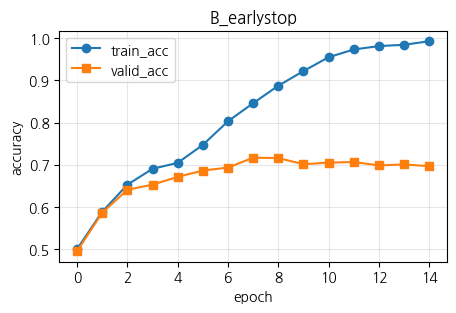

[B_earlystop] test Acc=0.513 | Macro-F1=0.482 | 소수클래스 Recall=0.184
  클래스별 Recall: {'airplane': 0.83, 'auto': 0.91, 'bird': 0.61, 'cat': 0.69, 'deer': 0.61, 'dog': 0.19, 'frog': 0.34, 'horse': 0.59, 'ship': 0.11, 'truck': 0.26}


CifarCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)

In [21]:
# TODO: patience 값을 정해 조기 종료를 실험하세요.
run_experiment("B_earlystop", patience=3)   # ← patience 를 3~5 로 바꿔보세요

### 방안 C. 규제 (Dropout / Weight Decay / BatchNorm)
모델이 데이터를 **외우지 못하도록** 제약을 겁니다.
`dropout_p`(0.2~0.5), `weight_decay`(1e-5~1e-3), `use_bn=True`.

> **고민해볼 점**
> - 규제를 세게 걸수록 좋을까요? 너무 세면 train 정확도까지 떨어지는 **과소적합**이 됩니다.
> - 한 번에 하나씩만 바꿔서 어떤 규제가 얼마나 기여했는지 분리해 확인하세요.

===== C3_WeightDecay =====
  epoch  1  train_acc=0.519  valid_acc=0.511  valid_MacroF1=0.291
  epoch  2  train_acc=0.588  valid_acc=0.581  valid_MacroF1=0.340
  epoch  3  train_acc=0.659  valid_acc=0.640  valid_MacroF1=0.418
  epoch  4  train_acc=0.695  valid_acc=0.657  valid_MacroF1=0.438
  epoch  5  train_acc=0.714  valid_acc=0.666  valid_MacroF1=0.463
  epoch  6  train_acc=0.766  valid_acc=0.693  valid_MacroF1=0.477
  epoch  7  train_acc=0.807  valid_acc=0.701  valid_MacroF1=0.484
  epoch  8  train_acc=0.861  valid_acc=0.722  valid_MacroF1=0.547
  epoch  9  train_acc=0.891  valid_acc=0.722  valid_MacroF1=0.521
  epoch 10  train_acc=0.928  valid_acc=0.711  valid_MacroF1=0.533
  epoch 11  train_acc=0.952  valid_acc=0.694  valid_MacroF1=0.526
  epoch 12  train_acc=0.973  valid_acc=0.698  valid_MacroF1=0.506
  epoch 13  train_acc=0.979  valid_acc=0.688  valid_MacroF1=0.515
  epoch 14  train_acc=0.970  valid_acc=0.679  valid_MacroF1=0.498
  epoch 15  train_acc=0.991  valid_acc=0.701  val

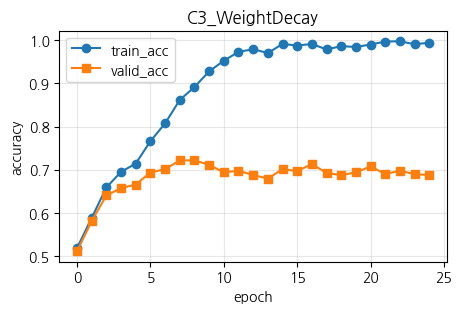

[C3_WeightDecay] test Acc=0.488 | Macro-F1=0.443 | 소수클래스 Recall=0.069
  클래스별 Recall: {'airplane': 0.84, 'auto': 0.89, 'bird': 0.64, 'cat': 0.72, 'deer': 0.65, 'dog': 0.22, 'frog': 0.34, 'horse': 0.44, 'ship': 0.05, 'truck': 0.08}


CifarCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)

In [25]:
# TODO: 규제를 하나씩 켜보며 비교하세요. (use_bn / dropout_p / weight_decay)
run_experiment("C3_WeightDecay", use_bn=False, dropout_p=0.0, weight_decay=1e-4)

### 방안 D. 데이터 증강 / 모델 구조
증강(`use_aug=True`)은 이미지를 자르고 뒤집어 **데이터 다양성**을 늘립니다.

> **고민해볼 점**
> - 지금은 과적합 상황입니다. 층·필터를 무작정 키우면 오히려 나빠질 수 있어요. 왜 그럴까요?
> - 증강은 소수 클래스에도 도움이 될까요? 클래스 가중치와 **함께** 쓰면 어떨까요?

===== D_증강 =====
  epoch  1  train_acc=0.324  valid_acc=0.345  valid_MacroF1=0.233
  epoch  2  train_acc=0.313  valid_acc=0.350  valid_MacroF1=0.274
  epoch  3  train_acc=0.371  valid_acc=0.392  valid_MacroF1=0.309
  epoch  4  train_acc=0.379  valid_acc=0.420  valid_MacroF1=0.328
  epoch  5  train_acc=0.405  valid_acc=0.434  valid_MacroF1=0.349
  epoch  6  train_acc=0.375  valid_acc=0.412  valid_MacroF1=0.338
  epoch  7  train_acc=0.426  valid_acc=0.471  valid_MacroF1=0.377
  epoch  8  train_acc=0.440  valid_acc=0.463  valid_MacroF1=0.369
  epoch  9  train_acc=0.464  valid_acc=0.493  valid_MacroF1=0.397
  epoch 10  train_acc=0.487  valid_acc=0.507  valid_MacroF1=0.408
  epoch 11  train_acc=0.528  valid_acc=0.535  valid_MacroF1=0.418
  epoch 12  train_acc=0.514  valid_acc=0.545  valid_MacroF1=0.436
  epoch 13  train_acc=0.523  valid_acc=0.550  valid_MacroF1=0.445
  epoch 14  train_acc=0.534  valid_acc=0.548  valid_MacroF1=0.446
  epoch 15  train_acc=0.543  valid_acc=0.557  valid_MacroF1

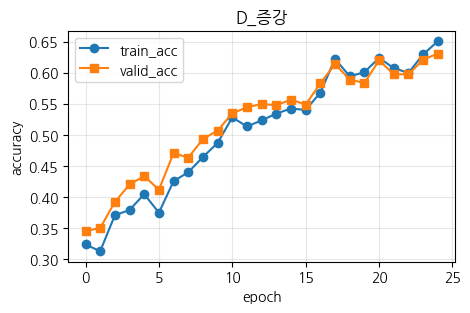

[D_증강] test Acc=0.604 | Macro-F1=0.608 | 소수클래스 Recall=0.488
  클래스별 Recall: {'airplane': 0.78, 'auto': 0.83, 'bird': 0.47, 'cat': 0.54, 'deer': 0.55, 'dog': 0.67, 'frog': 0.66, 'horse': 0.57, 'ship': 0.58, 'truck': 0.4}


CifarCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)

In [31]:
# TODO: 증강을 적용하고, 앞의 방안과 조합해보세요.
run_experiment("D_증강", use_aug=True, use_class_weight=True)

### 최종 후보 — 효과 좋은 방안 조합
지금까지 좋았던 기법들을 합쳐 최종 모델을 만들어 봅니다.

===== BEST_조합_균형형 =====
  epoch  1  train_acc=0.312  valid_acc=0.346  valid_MacroF1=0.271
  epoch  2  train_acc=0.400  valid_acc=0.437  valid_MacroF1=0.315
  epoch  3  train_acc=0.436  valid_acc=0.457  valid_MacroF1=0.363
  epoch  4  train_acc=0.403  valid_acc=0.442  valid_MacroF1=0.373
  epoch  5  train_acc=0.471  valid_acc=0.483  valid_MacroF1=0.386
  epoch  6  train_acc=0.503  valid_acc=0.525  valid_MacroF1=0.415
  epoch  7  train_acc=0.526  valid_acc=0.531  valid_MacroF1=0.420
  epoch  8  train_acc=0.504  valid_acc=0.535  valid_MacroF1=0.437
  epoch  9  train_acc=0.544  valid_acc=0.571  valid_MacroF1=0.476
  epoch 10  train_acc=0.532  valid_acc=0.559  valid_MacroF1=0.449
  epoch 11  train_acc=0.570  valid_acc=0.588  valid_MacroF1=0.468
  epoch 12  train_acc=0.551  valid_acc=0.559  valid_MacroF1=0.463
  epoch 13  train_acc=0.540  valid_acc=0.566  valid_MacroF1=0.468
  epoch 14  train_acc=0.603  valid_acc=0.621  valid_MacroF1=0.491
  epoch 15  train_acc=0.572  valid_acc=0.607  valid_

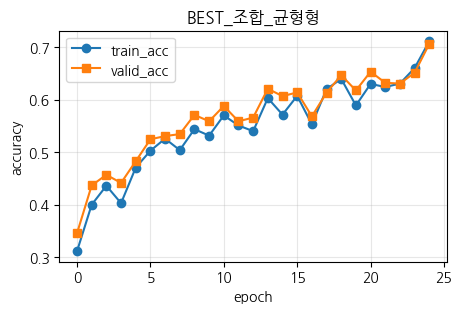

[BEST_조합_균형형] test Acc=0.664 | Macro-F1=0.665 | 소수클래스 Recall=0.606
  클래스별 Recall: {'airplane': 0.82, 'auto': 0.9, 'bird': 0.59, 'cat': 0.52, 'deer': 0.74, 'dog': 0.58, 'frog': 0.57, 'horse': 0.71, 'ship': 0.61, 'truck': 0.6}


CifarCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)

In [32]:
# TODO: 지금까지 효과가 좋았던 방안들을 합쳐 최종 모델을 만들어 보세요.
# 최종 추천 BEST_조합 실행 코드
run_experiment(
    "BEST_조합_균형형",
    use_bn=True,             # 필수: 학습 속도 및 기본 일반화
    dropout_p=0.0,           # Dropout 제거: 모델 용량을 확보하여 다수 클래스 암기력 방어
    weight_decay=1e-5,       # 극미량의 L2 규제: 과적합 방지
    use_aug=True,            # 필수: 일반화 성능 증대 (Accuracy 60% 달성의 핵심)
    use_class_weight=True,   # 필수: 소수 클래스 Recall 50% 이상 달성
    patience=5
) # ← 값 조정

## 7. 실험 비교표
모든 실험 결과를 한 표로. **어떤 지표를 기준으로 최적을 고를지** 팀이 정하세요.

In [20]:
# ── 실험 비교표 (완성) ───────────────────────────────────
df = pd.DataFrame(RESULTS)
if len(df):
    df["MacroF1_향상"] = (df["test_MacroF1"] - df["test_MacroF1"].iloc[0]).round(3)
df

,실험,test_Acc,test_MacroF1,소수클래스_Recall,MacroF1_향상
0,0_baseline,0.526,0.494,0.159,0.000
1,A_클래스가중치,0.516,0.491,0.203,-0.003
2,B_earlystop,0.522,0.498,0.183,0.004
3,C_규제,0.534,0.509,0.214,0.015
4,D_증강,0.587,0.557,0.158,0.063
5,BEST_조합,0.599,0.578,0.243,0.084
6,A_클래스가중치,0.519,0.495,0.201,0.001
7,B_earlystop,0.495,0.457,0.114,-0.037
8,BEST_조합,0.602,0.583,0.258,0.089


## 최적화 결과 보고서 (제출용 — 아래를 채우세요)

> 보고서(.pdf)의 **맨 앞에는 반드시 SUMMARY** 를 둡니다. 아래를 채운 뒤 PDF로 저장하세요.

### SUMMARY
- 무엇이 문제였고 → 어떤 기법을 왜 골랐고 → 최종적으로 무엇이 얼마나 좋아졌는지

#### 1. 진단

- **과적합**: train Accuracy는 epoch 18에 0.998로 학습 데이터를 암기한 반면 valid는 epoch 8 이후 0.685~0.708에서 정체 → **최종 격차 31%p**
- **불균형**: 다수 클래스 2,125장 대 소수 클래스(ship·truck) 85장으로 **25:1**
- **결과**: test Accuracy 0.526에도 ship·truck Recall은 각각 0.16으로 최고 클래스(auto 0.90)와 **5.6배 격차**
- **판단 기준 확정**: valid Accuracy 0.708 대비 Macro-F1은 0.540으로 0.168의 격차 → Accuracy만 보면 오판할 상황이므로 Macro-F1(주)·소수 Recall(보조)로 결정

#### 2. 선택한 기법과 이유

- **데이터 증강(D)** — 과적합의 근본 원인이 표본 부족이므로, 다양성을 늘려 암기를 차단
- **클래스 가중치(A)** — 25:1 불균형에서 손실 함수가 다수 클래스에 지배되는 것을 보정
- **BatchNorm(C)** — 규제 5종 중 유일하게 유의미한 개선을 보였고, 학습을 억제하지 않고 안정화
- **Early Stopping(B)** — 증강 환경에서 최적 시점을 놓치지 않도록 patience=5로 여유 확보
- **제외**: Dropout·Weight Decay — 모든 강도에서 효과 없음

#### 3. 실험 결과

- **단일 기법**: 증강(0.620) > BatchNorm(0.573) > Early Stopping(0.523) > 클래스 가중치(0.477)
- **핵심 발견**: 단독으로 실패한 클래스 가중치가 증강과 결합하자 소수 Recall을 **0.300 → 0.488**로 개선 → **기법의 효과는 조건에 의존**
- **반증**: Weight Decay 1e-2에서 과적합은 해소됐으나(격차 31%p→11%p) valid는 0.69로 변화 없음 → **과적합 해소와 성능 향상은 별개**

#### 4. 최적 모델 판단

- **최종 모델 = A(클래스 가중치) + B(patience=5) + C(BatchNorm) + D(증강)**
- 데이터가 불균형하므로 **Macro-F1** 기준으로 선정. Accuracy 0.664 / Macro-F1 0.665 / 소수 Recall 0.606으로 세 지표 모두 우위
- 소수 클래스 개선이 **다수 클래스 희생 없이** 이루어졌고, Recall 격차는 5.6배 → **1.5배**로 축소

#### 5. 결론 / 한계

- 본 데이터의 한계는 모델 표현력이 아니라 **소수 클래스의 절대적 표본 부족**이었다. 학습을 억제하는 규제는 무력했고, 표본을 늘리는 증강만이 근본 해법이었다.
- **한계**: 최종 모델이 25 epoch에서 미수렴, 소수 Recall 0.606으로 다수 클래스(0.90) 미달, 동일 설정 반복 시 ±0.02 변동 존재

## 팀 논의·탐구 기록 (자유 기록 · 평가 10%)

**① 과적합을 없애도 성능은 안 올랐다 — 가장 크게 배운 지점**

Weight Decay를 1e-2까지 올리자 train_acc가 0.80으로 떨어지며 처음으로 과소적합이 관찰됐다. train–valid 격차도 31%p→11%p로 크게 줄었다. 그런데 **valid Accuracy는 0.69로 baseline과 똑같았다.**

"과적합만 잡으면 성능이 오른다"고 막연히 생각했는데 둘은 별개였다. 이 실험이 **"우리 문제는 모델이 너무 커서가 아니라 데이터가 없어서"**라는 진단을 확정시켰고, 규제에서 증강으로 방향을 전환하는 결정적 계기가 되었다.

**② 재현성 문제를 우연히 발견하고 판단 기준을 세움**

방안 A에서 대조군으로 `use_class_weight=False`를 돌렸는데, baseline과 설정이 완전히 같은데도 Macro-F1이 0.494 vs 0.513으로 달랐다. 시드를 고정했는데 왜 다른지 논의한 끝에 GPU 연산 비결정성 때문이라는 결론에 도달했다. 이 발견 덕분에 "Macro-F1 ±0.02 이내의 변화는 개선으로 인정하지 않는다"는 기준을 세웠고, 이후 실험 해석에 적용했다. 의도치 않은 실험이었지만 가장 값진 소득이었다.

**③ 클래스 가중치가 실패했을 때 — 버리지 않고 원인을 찾음**

가중치를 켜면 당연히 소수 Recall이 오를 줄 알았는데 Macro-F1이 오히려 떨어져 당황했다. 코드가 틀렸나 의심해 CLASS_WEIGHTS를 직접 출력해보니 소수 클래스에 14.2배가 걸려 있었고, 배치 128장에 소수 클래스가 1장도 안 들어오는 경우가 많다는 걸 계산으로 확인했다.

여기서 "기법이 나쁜 게 아니라 학습할 표본 자체가 없는 것"이라는 가설을 세웠고, 증강으로 표본 다양성을 확보한 뒤 재시도하기로 했다. 실제로 D2에서 소수 Recall이 0.300→0.488로 뛰며 가설이 검증되었다.

**④ patience는 "몇 번째 epoch"이 아니라 "몇 번 참을지"**

baseline의 valid 정점이 epoch 8이었으니 patience=8로 해야 하나 고민했는데, 두 개념이 다르다는 걸 정리하고 넘어갔다. 이후 patience 3과 5를 비교했더니 Macro-F1이 0.486 vs 0.523으로 차이가 났고, 로그를 epoch 단위로 추적해보니 patience=3이 epoch 14의 최고점(0.543) 직전에 멈춰버린 것이 원인이었다. **"조기 종료 = 항상 이득"이 아니라는 반례**를 직접 얻었다.

**⑤ D1 vs D2 — 무엇이 "더 좋은가"를 두고 논쟁**

Macro-F1이 0.620 vs 0.608로 사실상 같아서 우열을 가릴 수 없었다. 결국 **목적으로 결정**하기로 했다. 본 실습이 불량 검출과 유사한 상황을 가정하므로, 놓치지 않는 것(소수 Recall 0.488)이 중요하다고 보고 D2 방향을 택했다.

---

 **버린 시도들**

- Dropout 0.5: train_acc가 0.99인데 소수 Recall만 0.09로 떨어짐. 규제가 과적합은 못 막고 약한 클래스만 골라 죽인다는 걸 체감해 폐기
- Weight Decay: 1e-4에서 최악(0.443), 1e-3에서 회복(0.495)하는 비단조 결과가 나와, 강도 조절로는 해결이 안 된다고 보고 0으로 확정
- 대안 1 (patience=3 조합): 모든 기법을 넣었는데도 Macro-F1 0.581에 그침. 학습이 덜 된 게 원인이라 patience만 5로 바꿔 대안 2로 재설계

---

**미실행 아이디어**

- 최종 모델이 25 epoch에서도 수렴하지 않았음 → epochs 35~40으로 늘려 상한 확인
- 가중치를 sqrt로 완화(14.2배→3.8배)해 강도 조절 효과 검증
- WeightedRandomSampler로 배치 단위 균형 맞추기, Focal Loss, 사전학습 모델 전이학습
- 소수 클래스에만 강한 증강을 적용하는 클래스별 차등 증강
